# Project 1 — Sprint 1: What drives baseball team success? (1960–2010)

**York University, School of Continuing Studies — Certificate in Big Data Analytics, Course 2 (Fall 2024)**
**Group 4:** Jinal, Yann, Olga, Reine

*Cleaned & verified rebuild of the October 2024 exploratory notebook (`baseball_teams.csv`).
Every code step carries a "why" comment; every claim below was re-executed against the data.*

## 1. Business question

A baseball front office wants to know **which team-level statistics actually move the win column**,
so it can decide where to invest: scoring more runs (offense), preventing runs (defense/pitching),
or both. Specifically:

1. What offensive traits are common among consistently high-performing teams?
2. How do defensive metrics (runs allowed, ERA, walks allowed, pitcher strikeouts) influence team success?
3. Can run-based indicators predict a team's win total?
4. Where should a team focus improvement effort — scoring, run prevention, or the balance of the two?

**Analytical plan:** exploratory data analysis (distributions, outliers, correlations) on team-season
statistics from the modern era, 1960–2010. No causal claims — association only.

In [ ]:
import pandas as pd          # data frames: the natural structure for a team-season table
import numpy as np           # numeric helpers (not strictly needed, but standard in this stack)
import matplotlib.pyplot as plt  # histograms & boxplots: the fastest honest look at a distribution

## 2. Data description

`baseball_teams.csv` — one row per team per season (Lahman-style team table), 43 columns.
We use a local copy under `data/` so the notebook runs anywhere without the original zip.

In [ ]:
from pathlib import Path
# WHY: in Jupyter, relative paths resolve from the folder where the SERVER was
# launched, not from this notebook's folder. This helper finds the project's
# data/ folder no matter where JupyterLab was started — no path to edit.
def _find_data_dir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base / "data", base / "projets" / "group4-project1-oct" / "data"):
            if cand.is_dir():
                return cand
    raise FileNotFoundError(
        "data/ folder not found. Open this notebook from inside the extracted pack "
        f"(kernel is running in: {Path.cwd()})"
    )
DATA = _find_data_dir()


# WHY read_csv on a local copy: the analysis must be reproducible anywhere —
# the data folder sits next to this notebook, so a relative path is used.
df = pd.read_csv(DATA / "baseball_teams.csv")
print("shape (rows, cols):", df.shape)
print("seasons:", int(df["Year "].min()), "to", int(df["Year "].max()))

In [ ]:
# WHY this check first: cumulative stats (runs, hits, wins) scale with games played.
# If season length varies wildly across eras, distributions and correlations are distorted.
print("Games played by era:")
print(df.groupby(df["Year "] < 1960)["Games_Played"].agg(["count", "min", "max"]))
print()
# WHY check missingness on exactly the columns we will use: a silent NaN would poison
# describe()/corr() without raising an error.
used = ["Year ", "Runs_Against", "Games_Lost", "Runs_Scored", "Games_Won",
        "Earned_Run_Average", "Hits", "Walks_Allowed", "Strikeouts_Allowed"]
print("missing values in columns we will use:")
print(df[used].isna().sum())

Games played by era:
       count  min  max
Year                  
False   1462  103  165
True    1343    6  162

missing values in columns we will use:
Year                  0
Runs_Against          0
Games_Lost            0
Runs_Scored           0
Games_Won             0
Earned_Run_Average    0
Hits                  0
Walks_Allowed         0
Strikeouts_Allowed    0
dtype: int64


**Finding & decision.** The raw file spans **1871–2015** (2,805 team-seasons). Before 1960, seasons
were as short as **6 games**; the modern era is a stable ~162-game schedule. Mixing eras would
contaminate every distribution with incomparable season totals, so **all analysis below uses the
1960–2010 window** (1,312 team-seasons) — the window the business question asks about. There are
no missing values in any column we use.

**Why these 8 variables** (2 outcomes, 2 offense, 4 defense/pitching):
- *Outcomes:* `Games_Won`, `Games_Lost` — the targets we want to explain.
- *Offense:* `Runs_Scored` (the direct product of batting), `Hits` (its main driver).
- *Defense/pitching:* `Runs_Against` (the direct cost), `Earned_Run_Average` (pitching quality,
  normalized per 9 innings so season length can't distort it), `Walks_Allowed` (free baserunners),
  `Strikeouts_Allowed` (despite the name, this column counts strikeouts **recorded by** the team's
  pitchers — higher means better pitching, as the correlation section will confirm).

In [ ]:
# WHY filter here, once: every later step (descriptives, plots, correlations) must speak
# about the same population, or the report contradicts itself.
modern = df[(df["Year "] >= 1960) & (df["Year "] <= 2010)].copy()

# WHY derive the run differential: the business question is offense vs defense vs the
# balance of the two. One number — runs scored minus runs allowed — captures "balance"
# directly instead of leaving it implied.
modern["Run_Differential"] = modern["Runs_Scored"] - modern["Runs_Against"]

v8 = ["Runs_Against", "Games_Lost", "Runs_Scored", "Games_Won",
      "Earned_Run_Average", "Hits", "Walks_Allowed", "Strikeouts_Allowed"]
print("analysis window rows:", len(modern))
print("mean run differential (sanity: must be ~0 across a league):",
      round(modern["Run_Differential"].mean(), 2))

analysis window rows: 1312
mean run differential (sanity: must be ~0 across a league): 0.0


## 3. Distributions — do we understand each variable before correlating anything?

**Why this order:** correlations are meaningless if a variable is dominated by outliers or a
broken scale. `describe()` gives center/scale, skewness quantifies asymmetry, histograms show
shape, boxplots expose outliers. Only then do we correlate.

In [ ]:
# WHY describe + skew together: means/stds tell us the playing field; skew tells us
# whether "average team" is a fair summary or a long tail is dragging it.
desc = modern[v8].describe().round(2)
print(desc.to_string())
print()
print("skewness (0 = symmetric; |.|>1 = strongly skewed):")
print(modern[v8].skew().round(2).to_string())

       Runs_Against  Games_Lost  Runs_Scored  Games_Won  Earned_Run_Average     Hits  Walks_Allowed  Strikeouts_Allowed
count       1312.00     1312.00      1312.00    1312.00             1312.00  1312.00        1312.00             1312.00
mean         703.45       79.52       703.45      79.52                4.01  1408.80         524.65              932.10
std          103.51       12.46       102.11      12.52                0.60   125.98          75.59              155.50
min          331.00       40.00       329.00      37.00                2.45   797.00         268.00              388.00
25%          640.00       71.00       641.00      71.00                3.58  1357.00         478.00              831.00
50%          701.00       79.00       704.00      80.00                3.97  1418.00         525.00              932.00
75%          770.25       88.00       771.00      89.00                4.39  1489.00         573.25             1038.25
max         1103.00      120.00      100

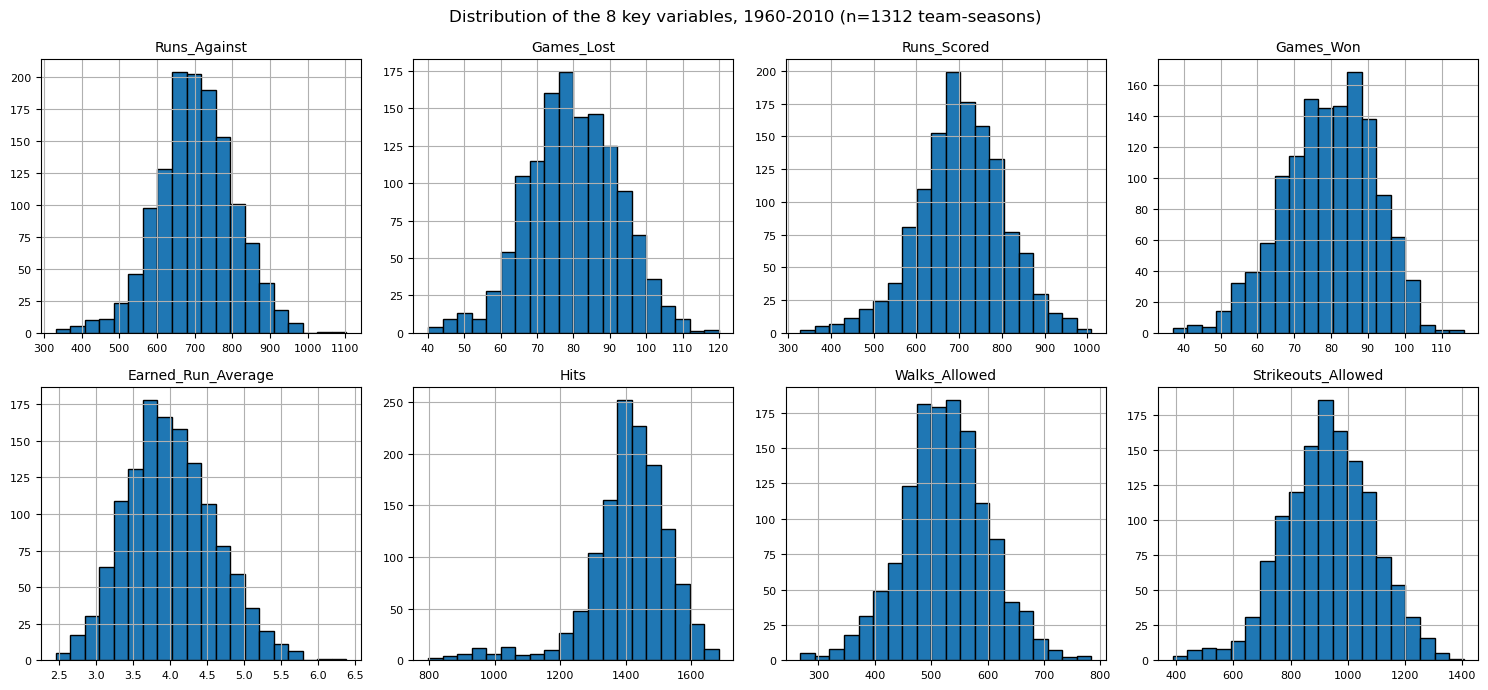

In [ ]:
# WHY histograms with 20 bins: enough resolution to see skew/bimodality, not so much
# that noise looks like structure. Same bins for all 8 keep the comparison honest.
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, v8):
    modern[col].hist(ax=ax, bins=20, edgecolor="black")
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
fig.suptitle("Distribution of the 8 key variables, 1960-2010 (n=1312 team-seasons)", fontsize=12)
plt.tight_layout()
plt.show()

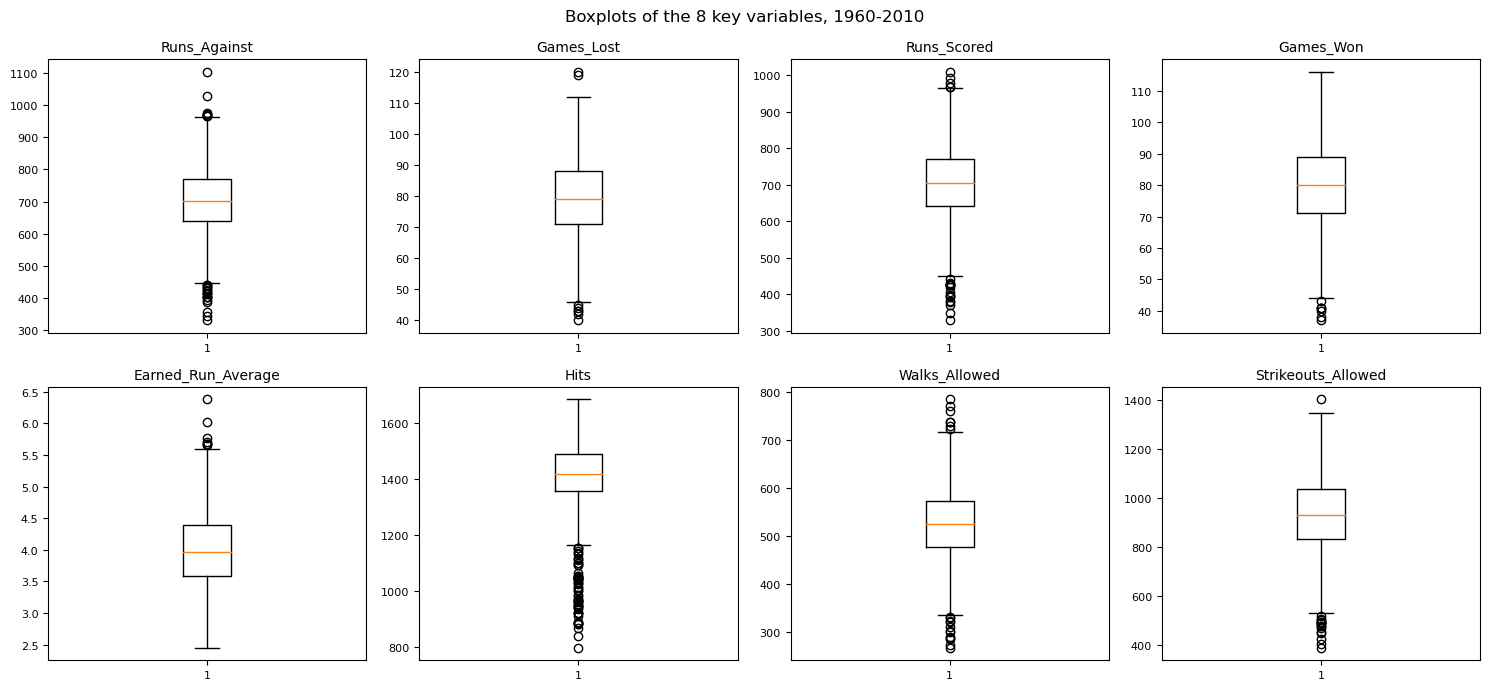

In [ ]:
# WHY boxplots: histograms hide exact outlier counts; boxplots show median vs mean
# asymmetry and flag the extreme seasons for follow-up.
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, v8):
    ax.boxplot(modern[col].dropna(), vert=True)
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
fig.suptitle("Boxplots of the 8 key variables, 1960-2010", fontsize=12)
plt.tight_layout()
plt.show()

### What the distributions actually show (corrected)

| Variable | Shape (1960–2010) | Note |
|---|---|---|
| Runs_Against | ~symmetric (skew −0.09), centered ~700 | No dominant outliers |
| Games_Lost | ~symmetric (skew −0.09), centered ~80 | Mirror of wins (seasons vary slightly in length) |
| Runs_Scored | ~symmetric, slight left tail (skew −0.20), centered ~704 | — |
| Games_Won | ~symmetric, slight left tail (skew −0.32), centered ~80 | — |
| Earned_Run_Average | Slightly **right**-skewed (skew +0.30), centered ~4.0 | Right tail = a few disastrous pitching seasons |
| Hits | **Left**-skewed (skew −1.43), centered ~1,418 | Left tail = strike-shortened seasons (1981, 1994, 1972): teams played ~103–117 games, so every counting stat collapsed |
| Walks_Allowed | ~symmetric (skew −0.07), centered ~525 | — |
| Strikeouts_Allowed | Wide spread (std ≈ 156), roughly symmetric, flat-topped peak ~830–1,040 | Not uniform — it trends upward across the 50-year window as pitching changed; wide because eras are pooled |

**On normality:** six of eight variables are close to symmetric; ERA leans right; Hits leans left
because of the strike seasons. None is perfectly normal, but with n = 1,312 Pearson correlations
are robust to this. For any later regression, Hits should be handled with care (flag the
shortened seasons rather than silently transforming them away).

## 4. Correlation analysis — offense vs defense vs balance

**Why Pearson correlation on these exact pairs:** the business questions ask "does scoring more /
allowing fewer go with winning more?" — for continuous season totals, Pearson's r is the direct,
standard measure of linear association. Each pair below maps to one business question; the
differential pairs test whether *balance* beats either side alone.

**a. Games Won vs Runs Scored** — does a better offense win more games?

In [ ]:
# WHY this pair: the purest "offense -> wins" test in the data.
print(modern[["Games_Won", "Runs_Scored"]].corr().round(4).to_string())

             Games_Won  Runs_Scored
Games_Won       1.0000       0.5958
Runs_Scored     0.5958       1.0000


**r = 0.60 — moderate positive.** Teams that score more runs tend to win more games. Offense clearly matters, but plenty of high-scoring teams still lose: scoring is not the whole story.

**b. Games Won vs Runs Against** — does a better defense win more games?

In [ ]:
# WHY this pair: the mirror test — "defense -> wins".
print(modern[["Games_Won", "Runs_Against"]].corr().round(4).to_string())

              Games_Won  Runs_Against
Games_Won        1.0000       -0.2482
Runs_Against    -0.2482        1.0000


**r = −0.25 — weak negative.** Allowing fewer runs is associated with winning slightly more, but the link is weak on its own. Run prevention alone explains little of the win column.

**c. Games Won vs Run Differential (Scored − Against)** — does the *balance* win?

In [ ]:
# WHY this pair: the head-to-head test of "balance beats one-sidedness".
print(modern[["Games_Won", "Run_Differential"]].corr().round(4).to_string())

                  Games_Won  Run_Differential
Games_Won            1.0000            0.8504
Run_Differential     0.8504            1.0000


**r = 0.85 — strong positive.** The differential dominates both components. Teams that outscore their opponents by a wide margin win — decisively more predictive than offense or defense alone.

**d. Games Lost vs Runs Scored**

In [ ]:
print(modern[["Games_Lost", "Runs_Scored"]].corr().round(4).to_string())

             Games_Lost  Runs_Scored
Games_Lost       1.0000      -0.2268
Runs_Scored     -0.2268       1.0000


**r = −0.23 — weak negative.** Scoring more is weakly associated with losing less. Consistent with (a): offense helps, but doesn't inoculate against losses.

**e. Games Lost vs Runs Against**

In [ ]:
print(modern[["Games_Lost", "Runs_Against"]].corr().round(4).to_string())

              Games_Lost  Runs_Against
Games_Lost        1.0000        0.6112
Runs_Against      0.6112        1.0000


**r = 0.61 — moderate positive.** Leaky defenses lose games: allowing more runs goes hand-in-hand with a bigger loss column. Defense shows up more clearly in *losses* than in *wins*.

**f. Games Lost vs Run Differential**

In [ ]:
print(modern[["Games_Lost", "Run_Differential"]].corr().round(4).to_string())

                  Games_Lost  Run_Differential
Games_Lost            1.0000           -0.8494
Run_Differential     -0.8494            1.0000


**r = −0.85 — strong negative.** The mirror of (c): a strongly positive differential goes with far fewer losses. Again, balance is the best single descriptor of team success.

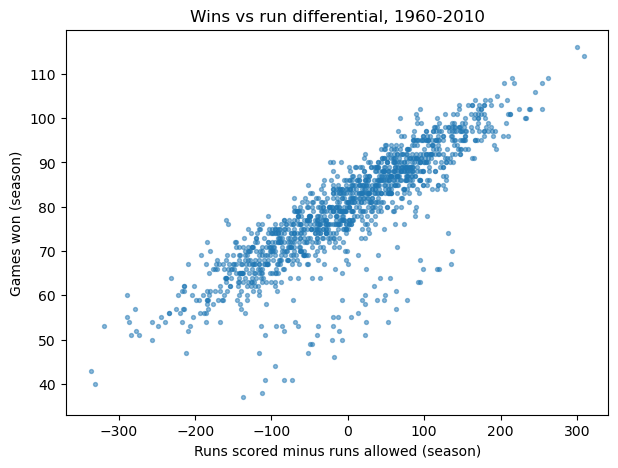

In [ ]:
# WHY one scatterplot: r = 0.85 is the headline number of this project; a plot checks
# that it is a genuine linear relationship and not driven by a few extreme seasons.
ax = modern.plot.scatter(x="Run_Differential", y="Games_Won", s=8, alpha=0.5,
                         figsize=(7, 5), title="Wins vs run differential, 1960-2010")
ax.set_xlabel("Runs scored minus runs allowed (season)")
ax.set_ylabel("Games won (season)")
plt.show()

## 5. Interpretation

**The run differential is the story.** At |r| ≈ 0.85 it explains team success far better than
offense alone (r = 0.60) or defense alone (r = −0.25). Teams that consistently outscore their
opponents win; teams that get outscored lose. This is the single number a front office should watch.

**Offense contributes more than defense alone — but balance wins.** Scoring runs (r = 0.60 with
wins) moves the needle more than preventing them (r = −0.25 with wins). The original draft
concluded from this that "offense definitely wins" — that overreaches: neither side alone comes
close to the differential's 0.85. The honest reading is symmetric: **a run prevented is worth
about as much as a run scored** (the win and loss correlations with the differential are near
mirror images, +0.85 / −0.85).

**Honest caveat.** The differential is close to a bookkeeping summary of winning: every game is
decided by who outscores whom, so a season-long differential *aggregates* game outcomes almost by
construction. It is the best in-sample descriptor here, not a causal lever you can pull
independently of scoring and prevention.

**Supporting notes.**
- Defense shows up cleanly through pitching quality: ERA correlates −0.44 with wins — a better
  normalized pitching metric than raw runs allowed.
- "Strikeouts_Allowed" is strikeouts *by* the team's pitchers (r = +0.35 with wins): more
  pitcher strikeouts = better defense, despite the confusing column name.
- Counting stats (Hits, Runs) from 1981, 1994 and 1972 are depressed by strike-shortened
  seasons — compare rates (like ERA), not raw totals, across those years.

## 6. Recommendation & next steps

1. **Optimize the differential, not one side of it.** Roster moves should be judged by net
   expected runs (runs added minus runs prevented). A run prevented ≈ a run scored.
2. **If forced to pick one lever, pick offense** — but expect diminishing returns without
   competent run prevention (the 0.60 vs −0.25 gap).
3. **Evaluate pitchers on ERA, not raw runs allowed**, and remember the column-name trap:
   pitcher strikeouts help; walks allowed hurt (weakly, r = −0.16 with wins).
4. **Next analytical step (not done here):** the original plan mentioned testing predictive
   models — fit a simple linear regression of wins on run differential as a baseline, then add
   ERA and Hits, and validate out-of-sample (e.g., train 1960–2000, test 2001–2010) before
   trusting it for decisions.

## Appendix — variable glossary

| Variable | Definition | Role in this analysis |
|---|---|---|
| Runs_Against | Runs opponents scored against the team (season) | Defense: direct cost |
| Games_Lost | Games the team lost | Outcome |
| Runs_Scored | Runs the team scored (season) | Offense: direct product |
| Games_Won | Games the team won | Outcome |
| Earned_Run_Average (ERA) | Earned runs allowed per 9 innings | Defense: pitching quality, season-length-proof |
| Hits | Base hits by the team's batters (season) | Offense: driver of runs |
| Walks_Allowed | Walks issued by the team's pitchers | Defense: free baserunners |
| Strikeouts_Allowed | **Strikeouts recorded by the team's pitchers** (column name is misleading) | Defense: pitching dominance |
| Run_Differential | Runs_Scored − Runs_Against (derived) | Balance of offense vs defense |